<a href="https://colab.research.google.com/github/Kaneko23/trabalho-m2.2-processamento-de-imagens/blob/main/M2_2_Kaue_Patrick_de_Brito(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# M2.2 - Filtragem na frequência, morfologia e segmentação
**Autor: Kauê Patrick de Brito**  
Universidade do Vale do Itajaí (UNIVALI)  
Disciplina: Processamento de Imagens | Professor: Felipe Viel  
Data: 16/11/2026

## Objetivo
Comparar Watershed e SLIC em uma imagem BSD500 original, com ruído gaussiano e filtrada na frequência. Depois aplicar limiarização, fechamento, preenchimento de buracos e abertura nas duas imagens indicadas pelo professor, com rotulagem e contagem próprias.

## Escolhas de implementação
As operações principais são manuais: máscara Gaussiana, Sobel, Watershed, SLIC em CIELAB, Otsu, dilatação, erosão, gap-filling e rotulagem. NumPy fornece matrizes, aritmética e FFT/IFFT. Pillow faz leitura e redimensionamento. Matplotlib exibe as imagens. Não são chamadas funções prontas de filtro, segmentação ou morfologia.


In [1]:
# @title Preparar as imagens do trabalho { display-mode: "form" }
# @markdown As imagens já estão incluídas no arquivo. Esta etapa apenas prepara os dados.
# @markdown Use **Executar tudo** para executar o trabalho completo.
# Dados originais incorporados para execução sem internet.
from pathlib import Path
import base64
DADOS_EM_BASE64 = {'procedencia.txt': 'RW50cmFkYXMgZG8gTTIuMi4gRGF0YXMgZGUgb2J0ZW7Dp8OjbzogMTYvMTEvMjAyNi4KYnNkXzMwOTYuanBnIFNIQTI1NiBjNjY0NzdmMDM2Yjg0ZDQ3OGUzMjJjOWNjMmJkMjU3OTY5ZDI5NTc5NTQ5YmNmN2YzNTA4N2YyZTQwZDE5ZmY1CmltYWdlbTEudGlmIFNIQTI1NiAxMmQ1NmQ1OTBiMmQwYzljNTBjMjc1YzBiMzVmOTA1OWQ2ODQ2YTQxMjRkNWZmNGY1N2YwMjM2NmJjOGI0NjU5CmltYWdlbTIucG5nIFNIQTI1NiAzOTIzYjdjNDQzNGM5MGRiMDU3NmIwM2M3OTRlMWFmYTFkZGE3NzdjNWRiNGMwZDlkMDc1YjVmN2JkMjkxZjNlCkxpbmtzIGRlIG9yaWdlbSBubyByZWxhdMOzcmlvIGUgbm8gbm90ZWJvb2suCg==', 'imagem1.tif': '...', 'imagem2.png': '...', 'bsd_3096.jpg': '...'}
Path('dados').mkdir(exist_ok=True)
for nome, conteudo in DADOS_EM_BASE64.items():
    Path('dados', nome).write_bytes(base64.b64decode(conteudo))
print('Três imagens disponíveis em dados/.')


Três imagens disponíveis em dados/.


## Ambiente e parâmetros


In [2]:
from pathlib import Path
from collections import deque
import heapq
import math
import json
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib import font_manager

# Arial quando instalada; alternativa para executar em ambientes sem essa fonte.
fontes = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams.update({'font.family': 'Arial' if 'Arial' in fontes else 'DejaVu Sans',
                     'font.size': 11, 'axes.titleweight': 'bold'})

BASE = Path('.')
DADOS = BASE / 'dados'
SAIDA = BASE / 'resultados'
SAIDA.mkdir(exist_ok=True)
SEMENTE = 42
SIGMA_RUIDO = 20.0
CORTE = 0.18              # fração da menor dimensão, em bins de frequência
K_SLIC = 100
COMPACTACAO = 10.0
ITERACOES = 6
PASSO_GRADIENTE = 8.0     # quantização fixa, igual nas três condições



## Leitura, cinza e métricas


In [3]:

def ler(caminho, maximo=None):
    im = Image.open(caminho).convert('RGB')
    if maximo and max(im.size) > maximo:
        escala = maximo / max(im.size)
        im = im.resize((round(im.width * escala), round(im.height * escala)))
    return np.asarray(im, dtype=float)


def cinza(rgb):
    if rgb.ndim == 2:
        return rgb.astype(float)
    return 0.299 * rgb[:, :, 0] + 0.587 * rgb[:, :, 1] + 0.114 * rgb[:, :, 2]


def limitar(a):
    return np.minimum(255, np.maximum(0, a))


def psnr(original, teste):
    erro = float(np.mean((original.astype(float) - teste.astype(float)) ** 2))
    return float('inf') if erro == 0 else 10 * math.log10(255 ** 2 / erro)



## Filtro Gaussiano no domínio da frequência
Aplica-se F = FFT(I), G = F × H e I_filtrada = IFFT(G). A máscara é H(u,v) = exp(-D²/(2D0²)). A extensão refletida de 32 pixels reduz efeitos da borda. D0 = 0,18 vezes a menor dimensão estendida. O filtro suave evita o corte abrupto de um passa-baixa ideal.

In [4]:

def filtrar_frequencia(imagem, corte=CORTE):
    # Reflexão reduz a descontinuidade das bordas na extensão periódica da FFT.
    h, w = imagem.shape[:2]
    p = 32
    pad = ((p, p), (p, p)) if imagem.ndim == 2 else ((p, p), (p, p), (0, 0))
    estendida = np.pad(imagem, pad, mode='reflect')
    H, W = estendida.shape[:2]
    y, x = np.indices((H, W))
    d2 = (y - H // 2) ** 2 + (x - W // 2) ** 2
    d0 = corte * min(H, W)
    mascara = np.exp(-d2 / (2 * d0 ** 2))
    # FFT é apenas a transformada. A resposta do filtro é calculada acima.
    F = np.fft.fftshift(np.fft.fft2(estendida, axes=(0, 1)), axes=(0, 1))
    G = F * (mascara if imagem.ndim == 2 else mascara[:, :, None])
    espacial = np.fft.ifft2(np.fft.ifftshift(G, axes=(0, 1)), axes=(0, 1)).real
    saida = limitar(espacial[p:p+h, p:p+w])
    return saida, mascara


def espectro(imagem):
    g = cinza(imagem)
    return np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(g))))



## Gradiente Sobel manual


In [5]:

def gradiente(imagem):
    g = cinza(imagem)
    h, w = g.shape
    p = np.pad(g, 1, mode='edge')
    kx = [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]
    ky = [[-1, -2, -1], [0, 0, 0], [1, 2, 1]]
    gx = np.zeros_like(g)
    gy = np.zeros_like(g)
    for i in range(3):
        for j in range(3):
            gx += kx[i][j] * p[i:i+h, j:j+w]
            gy += ky[i][j] * p[i:i+h, j:j+w]
    return np.sqrt(gx ** 2 + gy ** 2) / 4

V4 = [(-1, 0), (1, 0), (0, -1), (0, 1)]
V8 = V4 + [(-1, -1), (-1, 1), (1, -1), (1, 1)]



## Watershed manual por mínimos regionais e inundação
O relevo é o módulo do gradiente Sobel, quantizado em passos de 8. Cada mínimo regional é uma semente. A fila de prioridade expande a bacia pelo menor nível máximo encontrado no caminho; a distância e a ordem de inserção resolvem empates. Usa vizinhança 4 e não reserva pixels exclusivos para divisórias: os contornos são obtidos pela mudança de rótulo.

In [6]:

def minimos_regionais(niveis):
    h, w = niveis.shape
    visto = np.zeros((h, w), bool)
    marcadores = np.zeros((h, w), np.int32)
    numero = 0
    # Uma planície só é um mínimo se NENHUM vizinho de toda a planície é menor.
    for y in range(h):
        for x in range(w):
            if visto[y, x]:
                continue
            valor = niveis[y, x]
            fila = deque([(y, x)])
            visto[y, x] = True
            pontos = []
            minimo = True
            while fila:
                a, b = fila.popleft()
                pontos.append((a, b))
                for dy, dx in V4:
                    c, d = a + dy, b + dx
                    if 0 <= c < h and 0 <= d < w:
                        if niveis[c, d] < valor:
                            minimo = False
                        if not visto[c, d] and niveis[c, d] == valor:
                            visto[c, d] = True
                            fila.append((c, d))
            if minimo:
                numero += 1
                for a, b in pontos:
                    marcadores[a, b] = numero
    return marcadores


def watershed_manual(imagem):
    topo = np.floor(gradiente(imagem) / PASSO_GRADIENTE).astype(int)
    rotulos = minimos_regionais(topo)
    h, w = topo.shape
    custo = np.full((h, w), np.inf)
    distancia = np.full((h, w), np.inf)
    fila = []
    ordem = 0
    for y, x in zip(*np.where(rotulos > 0)):
        custo[y, x], distancia[y, x] = topo[y, x], 0
        heapq.heappush(fila, (int(topo[y, x]), 0, ordem, y, x))
        ordem += 1
    while fila:
        nivel, dist, _, y, x = heapq.heappop(fila)
        if (nivel, dist) != (custo[y, x], distancia[y, x]):
            continue
        for dy, dx in V4:
            a, b = y + dy, x + dx
            if 0 <= a < h and 0 <= b < w:
                novo = (max(nivel, int(topo[a, b])), dist + 1)
                if novo < (custo[a, b], distancia[a, b]):
                    custo[a, b], distancia[a, b] = novo
                    rotulos[a, b] = rotulos[y, x]
                    heapq.heappush(fila, (*novo, ordem, a, b))
                    ordem += 1
    # Empates usam ordem de inserção. As divisórias são extraídas dos rótulos.
    return rotulos



## RGB para CIELAB, calculado pelas equações


In [7]:

def rgb_lab(rgb):
    a = rgb / 255.0
    linear = np.where(a <= 0.04045, a / 12.92, ((a + 0.055) / 1.055) ** 2.4)
    matriz = np.array([[0.4124564, 0.3575761, 0.1804375],
                       [0.2126729, 0.7151522, 0.0721750],
                       [0.0193339, 0.1191920, 0.9503041]])
    xyz = linear @ matriz.T / np.array([0.95047, 1.0, 1.08883])
    delta = 6 / 29
    f = np.where(xyz > delta ** 3, np.cbrt(xyz), xyz / (3 * delta ** 2) + 4 / 29)
    return np.stack((116*f[:, :, 1]-16, 500*(f[:, :, 0]-f[:, :, 1]),
                     200*(f[:, :, 1]-f[:, :, 2])), axis=2)



## Conectividade dos superpixels


In [8]:

def corrigir_conectividade(labels, area_minima):
    h, w = labels.shape
    componentes = np.full((h, w), -1, int)
    tamanhos = []
    for y in range(h):
        for x in range(w):
            if componentes[y, x] >= 0:
                continue
            ident = len(tamanhos)
            fila = deque([(y, x)])
            componentes[y, x] = ident
            tamanho = 0
            while fila:
                a, b = fila.popleft()
                tamanho += 1
                for dy, dx in V4:
                    c, d = a+dy, b+dx
                    if 0 <= c < h and 0 <= d < w and componentes[c, d] < 0 and labels[c, d] == labels[y, x]:
                        componentes[c, d] = ident
                        fila.append((c, d))
            tamanhos.append(tamanho)
    adj = [set() for _ in tamanhos]
    for a, b in [(componentes[:-1], componentes[1:]),
                 (componentes[:, :-1], componentes[:, 1:])]:
        diferentes = a != b
        for u, v in zip(a[diferentes], b[diferentes]):
            adj[u].add(int(v)); adj[v].add(int(u))
    pai = list(range(len(tamanhos)))
    def raiz(a):
        while pai[a] != a:
            pai[a] = pai[pai[a]]
            a = pai[a]
        return a
    for i in sorted(range(len(tamanhos)), key=lambda j: tamanhos[j]):
        r = raiz(i)
        if r != i or tamanhos[r] >= area_minima:
            continue
        vizinhos = {raiz(j) for j in adj[r]} - {r}
        if vizinhos:
            destino = max(vizinhos, key=lambda j: (tamanhos[j], -j))
            pai[r] = destino
            tamanhos[destino] += tamanhos[r]
            adj[destino].update(adj[r])
    mapa = np.array([raiz(i) for i in range(len(pai))])
    _, indices = np.unique(mapa[componentes], return_inverse=True)
    return indices.reshape(h, w) + 1



## SLIC manual
SLIC agrupa cor e posição localmente. A distância quadrática é Dc² + (m/S)² Ds², em que Dc usa CIELAB e Ds usa coordenadas. K=100 é um alvo, não uma contagem garantida. Há seis iterações e correção da conectividade, com união de fragmentos menores que S²/4.

In [9]:

def slic_manual(rgb, k=K_SLIC, m=COMPACTACAO, iteracoes=ITERACOES):
    lab = rgb_lab(rgb)
    h, w = lab.shape[:2]
    passo = max(2, int(round(math.sqrt(h*w/k))))
    grad = gradiente(rgb)
    centros = []
    for y in range(passo//2, h, passo):
        for x in range(passo//2, w, passo):
            # Desloca a semente para o menor gradiente na janela 3x3.
            pontos = [(a, b) for a in range(max(0, y-1), min(h, y+2))
                             for b in range(max(0, x-1), min(w, x+2))]
            a, b = min(pontos, key=lambda p: grad[p])
            centros.append([*lab[a, b], a, b])
    centros = np.array(centros, dtype=float)
    Y, X = np.indices((h, w))
    for _ in range(iteracoes):
        distancias = np.full((h, w), np.inf)
        labels = np.full((h, w), -1, int)
        for i, centro in enumerate(centros):
            y, x = centro[3:]
            y0, y1 = max(0, int(y)-passo), min(h, int(y)+passo+1)
            x0, x1 = max(0, int(x)-passo), min(w, int(x)+passo+1)
            dc = np.sum((lab[y0:y1, x0:x1] - centro[:3])**2, axis=2)
            ds = (Y[y0:y1, x0:x1]-y)**2 + (X[y0:y1, x0:x1]-x)**2
            D = dc + (m/passo)**2 * ds
            melhor = D < distancias[y0:y1, x0:x1]
            distancias[y0:y1, x0:x1][melhor] = D[melhor]
            labels[y0:y1, x0:x1][melhor] = i
        # Segurança para imagens com proporções extremas.
        for y, x in zip(*np.where(labels < 0)):
            labels[y, x] = np.argmin(np.sum((centros[:, 3:] - [y, x])**2, axis=1))
        for i in range(len(centros)):
            mascara = labels == i
            if mascara.any():
                centros[i, :3] = lab[mascara].mean(axis=0)
                centros[i, 3:] = [Y[mascara].mean(), X[mascara].mean()]
    return corrigir_conectividade(labels, max(1, passo*passo//4))



## Otsu e morfologia binária manuais
Otsu escolhe o limiar que maximiza a variância entre duas classes. Fechamento é dilatação seguida de erosão. Gap-filling visita o fundo conectado às bordas e preenche o fundo restante. Abertura é erosão seguida de dilatação. O elemento estruturante é um quadrado 3×3.

In [10]:

def otsu(imagem):
    valores = limitar(imagem).astype(np.uint8)
    hist = np.zeros(256, int)
    for valor in valores.ravel():
        hist[valor] += 1
    total = valores.size
    soma = sum(i * int(hist[i]) for i in range(256))
    peso0, soma0, melhor, limiar = 0, 0, -1.0, 0
    for t in range(256):
        peso0 += int(hist[t]); soma0 += t * int(hist[t])
        peso1 = total-peso0
        if peso0 == 0 or peso1 == 0:
            continue
        media0, media1 = soma0/peso0, (soma-soma0)/peso1
        variancia = peso0*peso1*(media0-media1)**2
        if variancia > melhor:
            melhor, limiar = variancia, t
    return limiar


def morfologia(binaria, operacao, raio=1):
    # Elemento estruturante quadrado, (2r+1) x (2r+1).
    h, w = binaria.shape
    p = np.pad(binaria.astype(bool), raio, mode='constant', constant_values=False)
    saida = np.zeros((h, w), bool) if operacao == 'dilatar' else np.ones((h, w), bool)
    for dy in range(2*raio+1):
        for dx in range(2*raio+1):
            janela = p[dy:dy+h, dx:dx+w]
            if operacao == 'dilatar':
                saida |= janela
            else:
                saida &= janela
    return saida


def fechamento(b):
    # Borda com margem evita cortar objetos durante a sequência.
    p = np.pad(b, 2, mode='constant')
    r = morfologia(morfologia(p, 'dilatar'), 'erodir')
    return r[2:-2, 2:-2]


def abertura(b):
    return morfologia(morfologia(b, 'erodir'), 'dilatar')


def preencher_buracos(b):
    # Fundo 4-conexo complementar ao objeto 8-conexo.
    h, w = b.shape
    externo = np.zeros_like(b, dtype=bool)
    fila = deque()
    for y in range(h):
        for x in (0, w-1):
            if not b[y, x] and not externo[y, x]:
                externo[y, x] = True; fila.append((y, x))
    for x in range(w):
        for y in (0, h-1):
            if not b[y, x] and not externo[y, x]:
                externo[y, x] = True; fila.append((y, x))
    while fila:
        y, x = fila.popleft()
        for dy, dx in V4:
            a, c = y+dy, x+dx
            if 0 <= a < h and 0 <= c < w and not b[a, c] and not externo[a, c]:
                externo[a, c] = True; fila.append((a, c))
    return ~externo



## Rotulagem e contagem próprias (busca em largura)
Cada pixel branco ainda sem rótulo inicia uma busca em largura (BFS). Todos os brancos alcançáveis recebem o mesmo número. O objeto usa conectividade 8; o fundo do gap-filling usa conectividade 4. Objetos que tocam a borda são incluídos na contagem.

In [11]:

def rotular(b):
    h, w = b.shape
    labels = np.zeros((h, w), np.int32)
    numero = 0
    for y in range(h):
        for x in range(w):
            if not b[y, x] or labels[y, x] != 0:
                continue
            numero += 1
            labels[y, x] = numero
            fila = deque([(y, x)])
            while fila:
                a, c = fila.popleft()
                for dy, dx in V8:
                    u, v = a+dy, c+dx
                    if 0 <= u < h and 0 <= v < w and b[u, v] and labels[u, v] == 0:
                        labels[u, v] = numero
                        fila.append((u, v))
    return labels, numero



## Visualização e análise dos contornos


In [12]:

def bordas(labels):
    b = np.zeros(labels.shape, bool)
    b[:-1] |= labels[:-1] != labels[1:]
    b[:, :-1] |= labels[:, :-1] != labels[:, 1:]
    return b


def sobrepor(rgb, labels):
    a = limitar(rgb).astype(np.uint8).copy()
    a[bordas(labels)] = [255, 0, 0]
    return a


def colorir(labels):
    rng = np.random.default_rng(SEMENTE)
    cores = rng.uniform(0.15, 1, (int(labels.max())+1, 3))
    cores[0] = 0
    return cores[labels]


def figura(imagens, titulos, arquivo, colunas=3, tamanho=(13, 7)):
    linhas = math.ceil(len(imagens)/colunas)
    fig, axes = plt.subplots(linhas, colunas, figsize=tamanho, squeeze=False)
    for ax, im, titulo in zip(axes.ravel(), imagens, titulos):
        # Matplotlib espera RGB float em [0,1] ou uint8 em [0,255].
        exibida = im / 255.0 if im.ndim == 3 and im.dtype.kind == 'f' and im.max() > 1 else im
        ax.imshow(exibida, cmap='gray' if im.ndim == 2 else None)
        ax.set_title(titulo, fontsize=11)
        ax.axis('off')
    for ax in axes.ravel()[len(imagens):]:
        ax.axis('off')
    fig.tight_layout()
    fig.savefig(SAIDA / arquivo, dpi=150, bbox_inches='tight')
    plt.show()


def analisar_parte1(caminho):
    original = ler(caminho, 320)
    rng = np.random.default_rng(SEMENTE)
    ruidosa = limitar(original + rng.normal(0, SIGMA_RUIDO, original.shape))
    filtrada, mascara = filtrar_frequencia(ruidosa)
    imagens = [original, ruidosa, filtrada]
    nomes = ['Original', 'Com ruído', 'Filtrada']
    figura(imagens, nomes, '01_imagens.png', tamanho=(13, 4))
    e0, e1 = espectro(ruidosa), espectro(filtrada)
    fig, ax = plt.subplots(1, 3, figsize=(13, 4))
    for a, e, t in zip(ax[:2], [e0, e1], ['Espectro com ruído', 'Espectro após filtro']):
        a.imshow(e, cmap='gray', vmin=0, vmax=max(e0.max(), e1.max()))
        a.set_title(t); a.axis('off')
    ax[2].imshow(mascara, cmap='gray'); ax[2].set_title('Resposta Gaussiana H(u,v)'); ax[2].axis('off')
    fig.tight_layout(); fig.savefig(SAIDA/'02_espectros.png', dpi=150); plt.show()
    resultados, paines, titulos = [], [], []
    for metodo, funcao in [('Watershed', watershed_manual), ('SLIC', slic_manual)]:
        for nome, im in zip(nomes, imagens):
            labels = funcao(im)
            n = len(np.unique(labels))
            # Contorno sempre sobre a mesma original, na mesma escala.
            paines.append(sobrepor(original, labels))
            titulos.append(f'{metodo}: {nome} ({n} regiões)')
            suporte = float(gradiente(original)[bordas(labels)].mean())
            resultados.append({'metodo': metodo, 'condicao': nome, 'regioes': n,
                               'gradiente_medio_no_contorno': round(suporte, 3)})
    figura(paines, titulos, '03_segmentacoes.png', tamanho=(14, 9))
    # Recorte idêntico de 100 x 120 pixels nas seis comparações.
    h, w = original.shape[:2]
    y0, x0 = h//3, w//3
    figura([a[y0:y0+100, x0:x0+120] for a in paines], titulos,
           '04_recorte.png', tamanho=(14, 8))
    metricas = {'dimensoes': list(original.shape), 'psnr_ruido': psnr(original, ruidosa),
                'psnr_filtrada': psnr(original, filtrada), 'segmentacao': resultados}
    print(json.dumps(metricas, ensure_ascii=False, indent=2))
    return metricas



## Parte 2: todas as etapas e contagem intermediária


In [13]:

def analisar_parte2(caminho, nome, objetos_escuros=False):
    rgb = ler(caminho, 800)
    g = cinza(rgb)
    t = otsu(g)
    b = g <= t if objetos_escuros else g > t
    fechada = fechamento(b)
    preenchida = preencher_buracos(fechada)
    final = abertura(preenchida)
    mascaras = [b, fechada, preenchida, final]
    nomes = ['Limiarização', 'Fechamento', 'Gap-filling', 'Abertura']
    contagens = []
    for etapa, mascara in zip(nomes, mascaras):
        labels, n = rotular(mascara)
        contagens.append({'etapa': etapa, 'objetos': n, 'area_pixels': int(mascara.sum())})
    labels, n = rotular(final)
    figura([g, b, fechada, preenchida, final, colorir(labels)],
           [f'{nome}: cinza', f'Otsu (T={t})', 'Fechamento 3x3', 'Preenchimento de buracos',
            'Abertura 3x3', f'Rótulos finais: {n} objetos'], f'05_{nome}.png', tamanho=(13, 8))
    # Mesmo recorte nas etapas binária e preenchida: evidencia buracos internos.
    h, w = b.shape
    y0, x0 = h//5, w//5
    figura([b[y0:y0+180, x0:x0+180], preenchida[y0:y0+180, x0:x0+180]],
           ['Após limiarização: detalhe', 'Após fechamento e gap-filling: detalhe'],
           f'06_detalhe_{nome}.png', colunas=2, tamanho=(8, 4))
    resultado = {'imagem': nome, 'dimensoes': list(g.shape), 'limiar_otsu': t,
                 'objetos_escuros': objetos_escuros, 'contagens': contagens,
                 'pixels_preenchidos': int(np.sum(preenchida & ~fechada))}
    print(json.dumps(resultado, ensure_ascii=False, indent=2))
    return resultado



## Testes pequenos de comportamento conhecido


In [14]:

def testes():
    b = np.zeros((12, 12), bool)
    b[2:6, 2:6] = True; b[3:5, 3:5] = False
    b[8:10, 8:10] = True
    p = preencher_buracos(b)
    assert rotular(b)[1] == rotular(p)[1] == 2
    assert p.sum() - b.sum() == 4
    assert not p[0, 0]
    assert rotular(np.zeros((5, 5), bool))[1] == 0
    assert rotular(np.ones((5, 5), bool))[1] == 1
    assert rotular(np.eye(4, dtype=bool))[1] == 1  # conectividade 8
    constante = np.full((16, 16, 3), 80.0)
    filtrada, _ = filtrar_frequencia(constante)
    assert np.max(np.abs(filtrada-constante)) < 1e-8
    assert np.unique(watershed_manual(constante)).size == 1
    assert np.isfinite(slic_manual(constante, k=4)).all()
    print('Testes OK: buracos, contagem, conectividade, FFT e imagem constante.')



## Parte 1 - Experimento e metodologia de comparação
Imagem **3096.jpg**, presente na divisão de validação do BSD500, carregada de uma cópia do conjunto. Resolução original: 481×321; processamento: 320×214. A mesma imagem limpa é referência para o PSNR RGB (faixa 0 a 255). Ruído aditivo gaussiano com desvio 20 e semente 42, seguido de limitação à faixa válida.

Aplicam-se os mesmos parâmetros de segmentação às três condições. Os contornos vermelhos são sobrepostos à **mesma imagem original**, em escala e recorte iguais. Além da quantidade de regiões, observa-se a preservação do avião e os contornos indevidos no céu. A média do gradiente da original sob os contornos mede apoio em transições de intensidade, mas **não é acurácia**. Não se usaram anotações humanas de referência. SSIM é opcional no enunciado e não foi incluído.


Testes OK: buracos, contagem, conectividade, FFT e imagem constante.


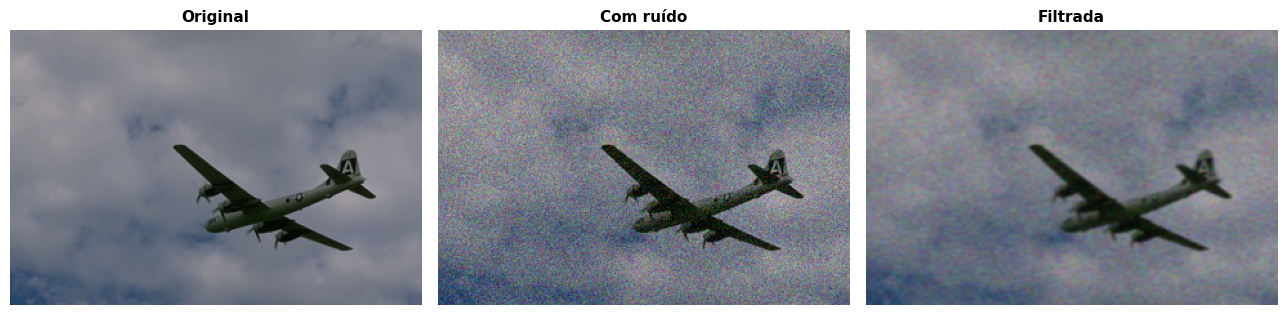

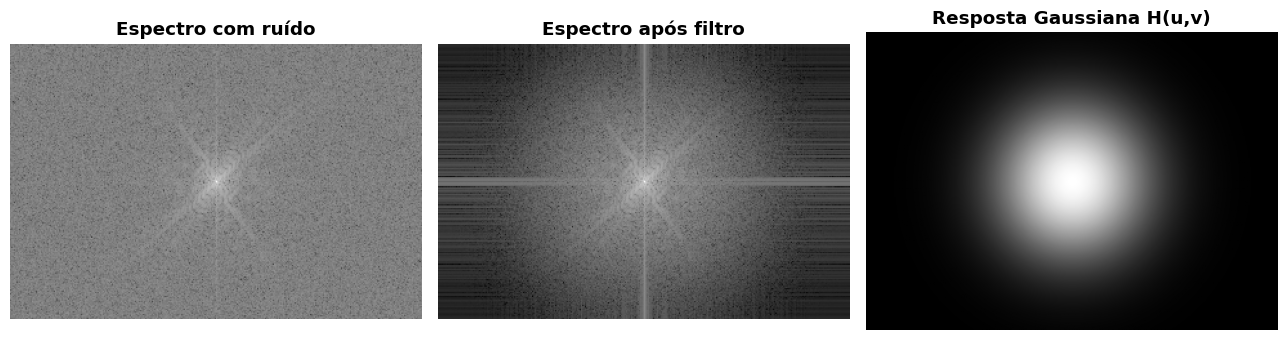

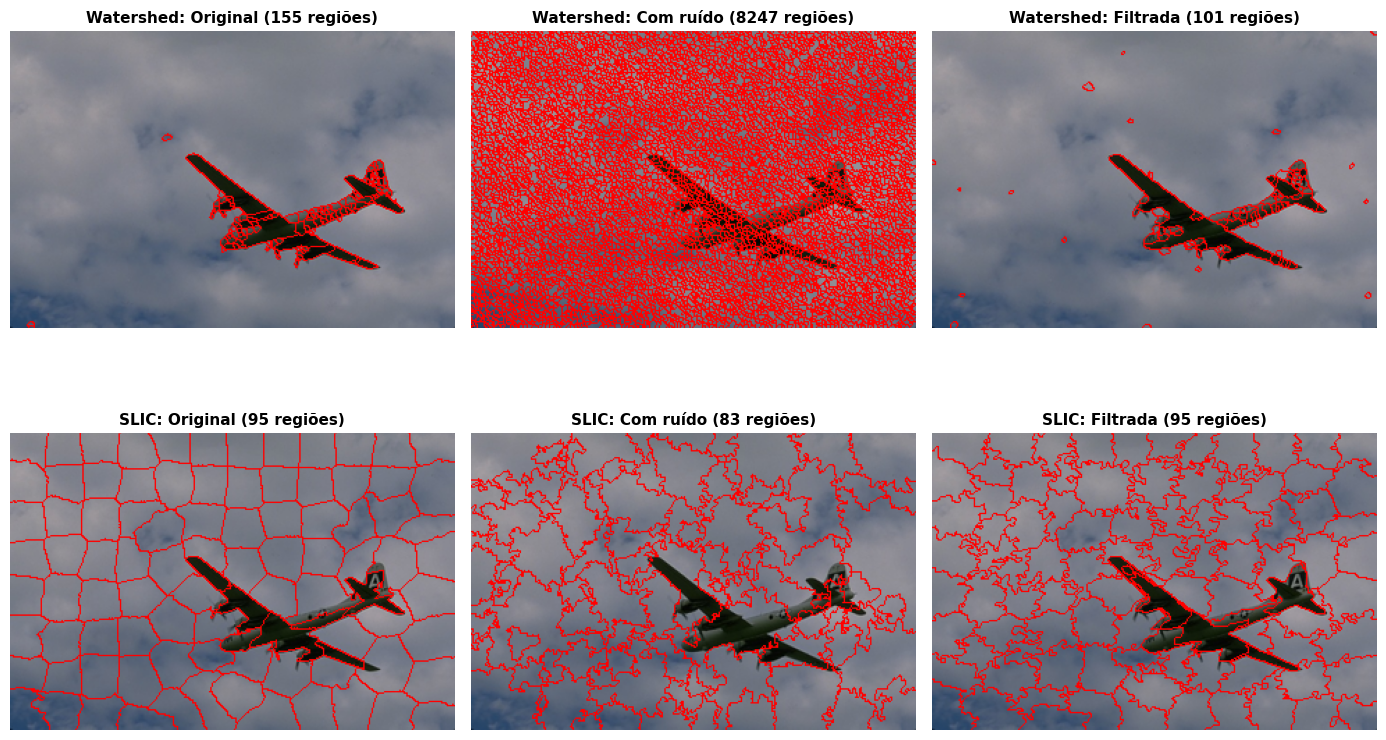

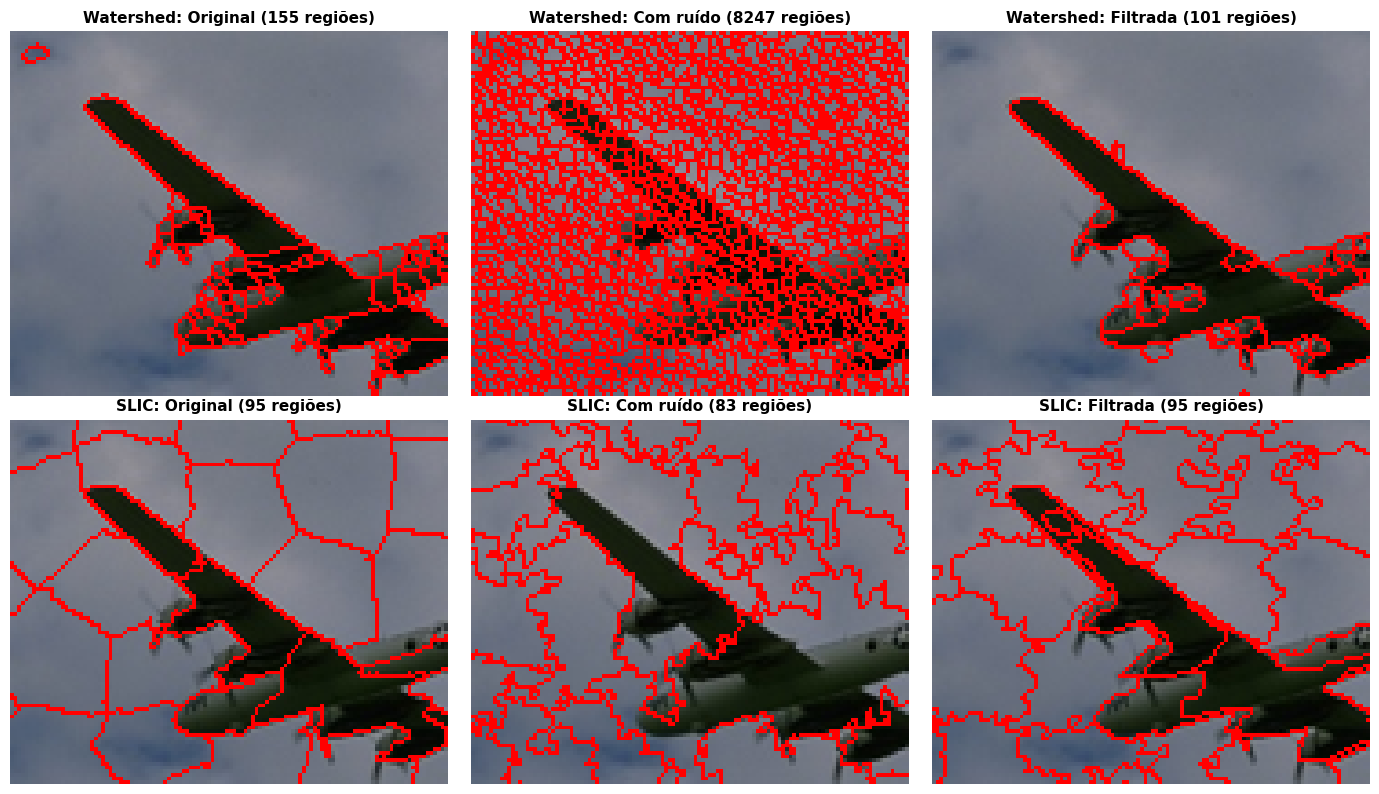

{
  "dimensoes": [
    214,
    320,
    3
  ],
  "psnr_ruido": 22.138365888329098,
  "psnr_filtrada": 31.589925930351423,
  "segmentacao": [
    {
      "metodo": "Watershed",
      "condicao": "Original",
      "regioes": 155,
      "gradiente_medio_no_contorno": 56.362
    },
    {
      "metodo": "Watershed",
      "condicao": "Com ruído",
      "regioes": 8247,
      "gradiente_medio_no_contorno": 4.904
    },
    {
      "metodo": "Watershed",
      "condicao": "Filtrada",
      "regioes": 101,
      "gradiente_medio_no_contorno": 52.281
    },
    {
      "metodo": "SLIC",
      "condicao": "Original",
      "regioes": 95,
      "gradiente_medio_no_contorno": 14.685
    },
    {
      "metodo": "SLIC",
      "condicao": "Com ruído",
      "regioes": 83,
      "gradiente_medio_no_contorno": 5.97
    },
    {
      "metodo": "SLIC",
      "condicao": "Filtrada",
      "regioes": 95,
      "gradiente_medio_no_contorno": 9.888
    }
  ]
}


In [15]:
testes()
resultado1 = analisar_parte1(DADOS/'bsd_3096.jpg')


## Parte 2 - Imagens indicadas pelo professor
A imagem 1 é uma figura binária de objetos com buracos, em 512×512. A imagem 2 é uma imagem de sangue, com 1600×1200 pixels na origem e 800×600 no processamento. Não se atribui origem BBBC006 a esses arquivos: usam-se exatamente os dois links do enunciado.

Os objetos da imagem 1 são claros. Os objetos da imagem 2 são escuros em relação ao fundo, portanto a comparação com o limiar é invertida. Não se aplicou o filtro espacial opcional. A contagem aparece após cada operação, para distinguir seu efeito do efeito do gap-filling.


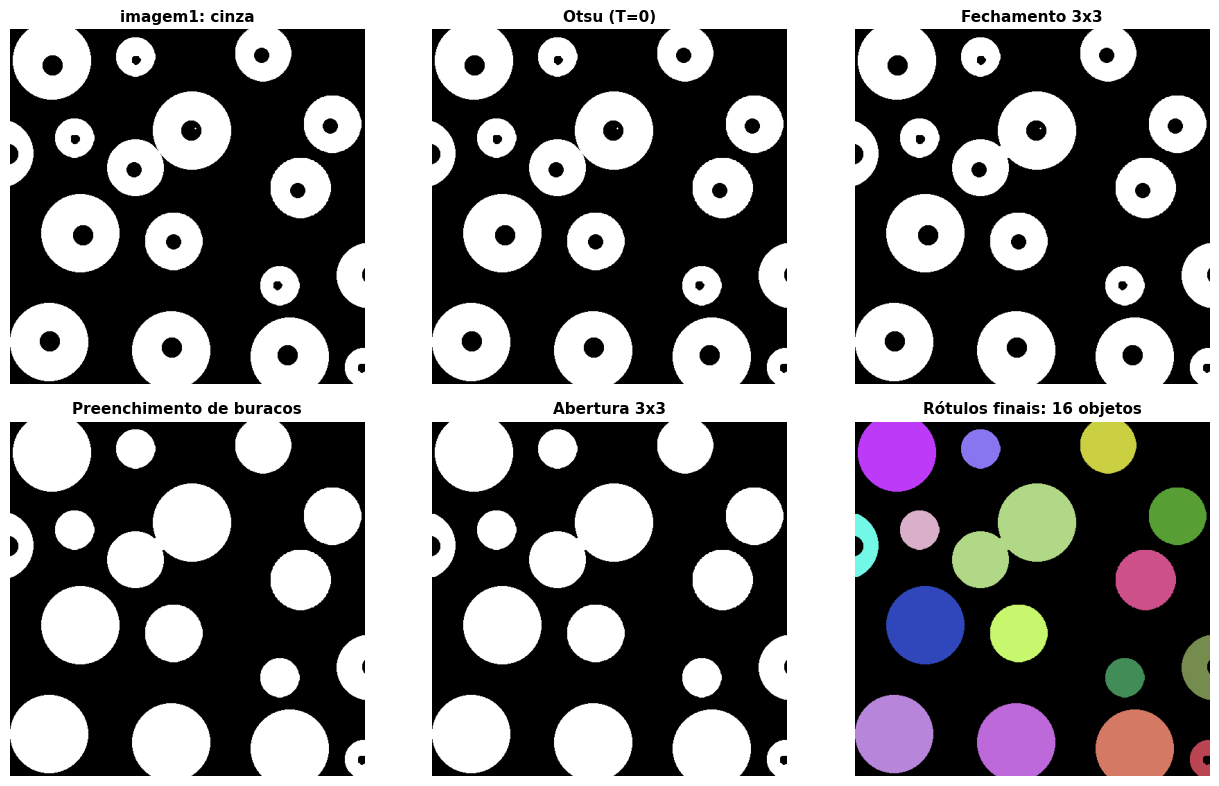

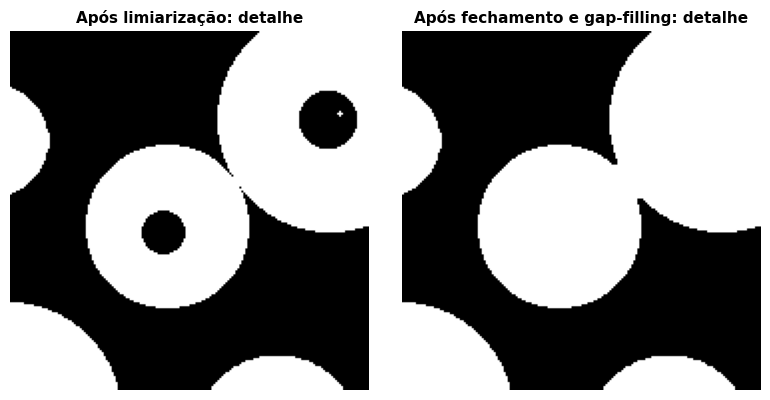

{
  "imagem": "imagem1",
  "dimensoes": [
    512,
    512
  ],
  "limiar_otsu": 0,
  "objetos_escuros": false,
  "contagens": [
    {
      "etapa": "Limiarização",
      "objetos": 17,
      "area_pixels": 92581
    },
    {
      "etapa": "Fechamento",
      "objetos": 17,
      "area_pixels": 92600
    },
    {
      "etapa": "Gap-filling",
      "objetos": 16,
      "area_pixels": 98918
    },
    {
      "etapa": "Abertura",
      "objetos": 16,
      "area_pixels": 98913
    }
  ],
  "pixels_preenchidos": 6318
}


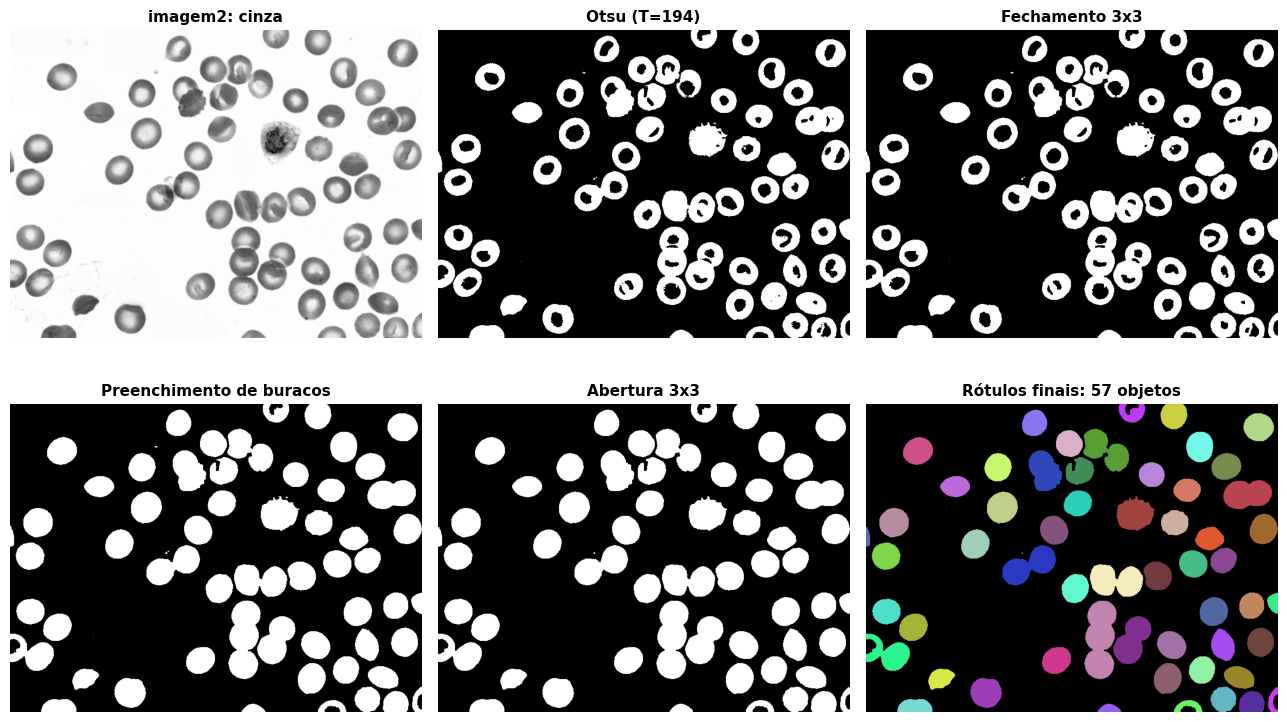

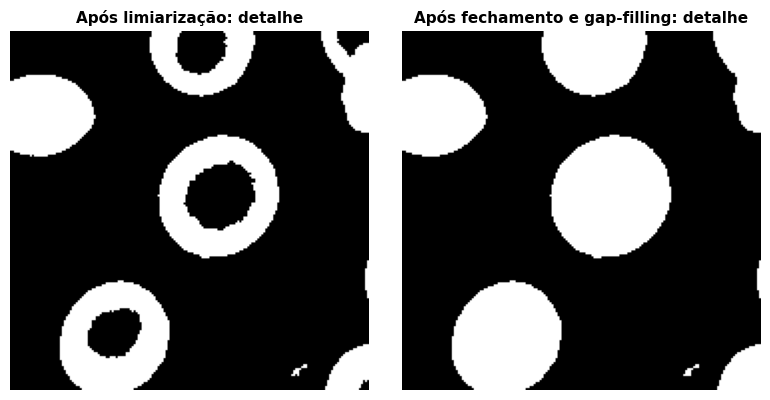

{
  "imagem": "imagem2",
  "dimensoes": [
    600,
    800
  ],
  "limiar_otsu": 194,
  "objetos_escuros": true,
  "contagens": [
    {
      "etapa": "Limiarização",
      "objetos": 83,
      "area_pixels": 114488
    },
    {
      "etapa": "Fechamento",
      "objetos": 63,
      "area_pixels": 115308
    },
    {
      "etapa": "Gap-filling",
      "objetos": 63,
      "area_pixels": 134581
    },
    {
      "etapa": "Abertura",
      "objetos": 57,
      "area_pixels": 134456
    }
  ],
  "pixels_preenchidos": 19273
}


2395

In [16]:
resultado2 = [analisar_parte2(DADOS/'imagem1.tif', 'imagem1'),
              analisar_parte2(DADOS/'imagem2.png', 'imagem2', objetos_escuros=True)]
resultados = {'parte1': resultado1, 'parte2': resultado2}
(SAIDA/'metricas.json').write_text(json.dumps(resultados, ensure_ascii=False, indent=2), encoding='utf-8')


## Análise dos resultados desta execução
O PSNR passou de **22,14 dB** para **31,59 dB**. O filtro reduziu o ruído, embora suavize detalhes. No Watershed, a quantidade de regiões passou de 8.247 com ruído para 101 após o filtro; na original foram 155. Menos regiões não significa automaticamente segmentação perfeita: o avião ainda contém divisões internas e detalhes podem se perder.

No SLIC foram 95, 83 e 95 regiões na original, na ruidosa e na filtrada. O número depende da grade inicial e da correção de conectividade. Os contornos da filtrada ainda ficam mais irregulares no céu do que na original. Não se conclui que SLIC recuperou a segmentação limpa apenas porque o total voltou a 95.

Na imagem 1, as contagens foram **17 / 17 / 16 / 16**, respectivamente após Otsu, fechamento, gap-filling e abertura. A queda durante o preenchimento tem uma explicação concreta: uma ilha branca de 5 pixels, dentro de um buraco, incorpora-se à região ao redor. Dois discos centrais também permanecem unidos. Otsu retorna T=0 porque a imagem já é binária, o que é válido.

Na imagem 2, as contagens foram **83 / 63 / 63 / 57**. O gap-filling preencheu 19.273 pixels e manteve a contagem em 63 nessa etapa. A redução final decorre da sequência de fechamento e abertura. Há aglomerados, objetos cortados nas bordas e detritos. **57 é o número de componentes conectados finais, sem validação de uma contagem biológica real.**

## Conclusão
O pré-processamento ajudou especialmente o Watershed, que foi sensível ao ruído. SLIC produziu superpixels e manteve dependência dos parâmetros. A morfologia corrigiu buracos e pequenos defeitos, mas não resolveu células encostadas. A rotulagem própria contou automaticamente as regiões obtidas. Os resultados atendem à comparação proposta, com limites explícitos de resolução, parâmetros e ausência de referência manual.


## Referências e procedência
- ARBELÁEZ, P. et al. Contour Detection and Hierarchical Image Segmentation. IEEE TPAMI, v. 33, n. 5, p. 898-916, 2011. BSD500: https://www2.eecs.berkeley.edu/Research/Projects/CS/vision/grouping/resources.html
- Imagem 3096.jpg (BSD500/val): https://raw.githubusercontent.com/BIDS/BSDS500/master/BSDS500/data/images/val/3096.jpg
- ACHANTA, R. et al. SLIC Superpixels Compared to State-of-the-art Superpixel Methods. IEEE TPAMI, v. 34, n. 11, p. 2274-2282, 2012. https://www.epfl.ch/labs/ivrl/research/slic-superpixels/
- VINCENT, L.; SOILLE, P. Watersheds in Digital Spaces: An Efficient Algorithm Based on Immersion Simulations. IEEE TPAMI, v. 13, n. 6, p. 583-598, 1991. O código adota uma variante didática com fila de prioridade.
- GONZALEZ, R. C.; WOODS, R. E. Digital Image Processing. 4. ed. Pearson, 2018.
- Imagem 1 do enunciado: https://github.com/VielF/ColabProjects/blob/main/dataset/OperacaoMorfologia/gap-region-filling.tif
- Imagem 2 do enunciado: https://github.com/VielF/ColabProjects/blob/main/dataset/OperacaoMorfologia/002f20ad-2ace-499c-9335-c9080bc3e6b5.png

